# FML 2026 Challenge: Analysis and Prediction over Bike Sharing Data

## Imports and Data Loading

In [160]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.utils import resample

from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV

In [161]:
df_bikes = pd.read_csv("../csv/bikes.csv")
df_bike_types = pd.read_csv("../csv/bike_types.csv")
df_stations = pd.read_csv("../csv/stations.csv")
df_cities = pd.read_csv("../csv/cities.csv")
df_stations_status = pd.read_csv("../csv/stations_status.csv")
df_trips_small = pd.read_csv("../csv/trips_small.csv")

## Data Exploration and Preprocessing Task

This part of the notebook presents an initial exploration and preprocessing of data from a bike-sharing system. It helps understand the structure, content, and quality of the different datasets before conducting further analysis.

For each dataset, several analyses are performed:

- previewing the first rows;
- examining data types and descriptive statistics;
- identifying missing values and duplicates;
- determining the number of unique values;
- analyzing key categorical and numerical variables;
- visualizing distributions using charts.

The visualizations mainly use bar charts, pie charts, and missing-value heatmaps created with Matplotlib and Seaborn.

### Exploration of `bikes.csv`

In [162]:
df_bikes.head()

,id,bike_type_id,computer_id
0,400481,196,83300002927
1,374044,204,7551171765
2,373778,204,7551140444
3,34749,14,0
4,88359,143,7551052355


In [163]:
df_bikes.info()

<class 'pandas.DataFrame'>
RangeIndex: 88436 entries, 0 to 88435
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id            88436 non-null  int64
 1   bike_type_id  88436 non-null  int64
 2   computer_id   88436 non-null  int64
dtypes: int64(3)
memory usage: 2.0 MB


This table serves as an intermediate link between bikes and their corresponding types. No modifications were required, as all values are non-null and the data types are correct.

### Exploration of `bike_types.csv`

In [164]:
df_bike_types.head()

,id,vehicle_image,name,description,form_factor,rider_capacity,propulsion_type,max_range,battery_capacity
0,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [165]:
df_bike_types.info()

<class 'pandas.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                121 non-null    int64  
 1   vehicle_image     91 non-null     str    
 2   name              91 non-null     str    
 3   description       51 non-null     str    
 4   form_factor       91 non-null     str    
 5   rider_capacity    91 non-null     float64
 6   propulsion_type   91 non-null     str    
 7   max_range         15 non-null     float64
 8   battery_capacity  22 non-null     float64
dtypes: float64(3), int64(1), str(5)
memory usage: 8.6 KB


In [166]:
df_bike_types[["rider_capacity", "max_range", "battery_capacity"]].describe()

,rider_capacity,max_range,battery_capacity
count,91.000000,15.0,22.000000
mean,1.230769,60000.0,547.727273
std,0.423659,0.0,61.638873
min,1.000000,60000.0,500.000000
25%,1.000000,60000.0,500.000000
50%,1.000000,60000.0,500.000000
75%,1.000000,60000.0,600.000000
max,2.000000,60000.0,690.000000


In [167]:
print("Number of duplicates : ", df_bike_types.duplicated().sum())

null_counts = df_bike_types.isnull().sum()
null_percentages = (null_counts / len(df_bike_types) * 100).round(2)
null_df = pd.DataFrame({
    "Number of null values": null_counts,
    "Percentage of null values (%)": null_percentages
})

print("Number of null values per column :")
print(null_df)

Number of duplicates :  0
Number of null values per column :
                  Number of null values  Percentage of null values (%)
id                                    0                           0.00
vehicle_image                        30                          24.79
name                                 30                          24.79
description                          70                          57.85
form_factor                          30                          24.79
rider_capacity                       30                          24.79
propulsion_type                      30                          24.79
max_range                           106                          87.60
battery_capacity                     99                          81.82


#### Cleaning Data

##### Column: `name`

In [168]:
df_bike_types["name"].unique()

<StringArray>
[                              nan,                         'Comfort',
   'Rower z fotelikiem dziecięcym',                          'Tandem',
                 'Elektricno kolo',                     'e-CARGObike',
            'Rowerek dziecięcy 6+',     '3-rychlostní SMARTbike 2.0.',
       'e-SMARTbike 2.0 with RFID',         '28 Zoll - Tourenfahrrad',
                'e-SMARTbike 2.0.',          'Smartbike 2.0 (B) 2019',
                 'e-SMARTbike 1.0',                       'UsedomRad',
               'UsedomRad Classic',         '20 Zoll - Kinderfahrrad',
         '24 Zoll - Kinderfahrrad',                 'Z wałem kardana',
          '7-rychlostní SMARTbike',                 'e-Bike "LaBigi"',
                          'E-Bike',     '7-rychlostní SMARTbike 2.0.',
                     'e-Cargobike',                       'CARGObike',
     '8-rychlostní SMARTbike 2.0.',                  'with Framelock',
          '8-rychlostní SMARTbike',            'CARGObike (3 wh

##### Column: `propulsion_type`

In [169]:
print(df_bike_types["propulsion_type"].unique())
df_bike_types.loc[df_bike_types["propulsion_type"] == "electric_assist", "propulsion_type"] = "electric"

<StringArray>
[nan, 'human', 'electric_assist']
Length: 3, dtype: str


##### Column: `form_factor`

In [170]:
print(df_bike_types["form_factor"].unique())
df_bike_types.loc[df_bike_types["form_factor"] == "bicycle", "form_factor"] = "regular"
df_bike_types.loc[df_bike_types["form_factor"] == "cargo_bicycle", "form_factor"] = "cargo"

<StringArray>
[nan, 'bicycle', 'cargo_bicycle', 'other']
Length: 4, dtype: str


#### Missing Values Analysis and Handling

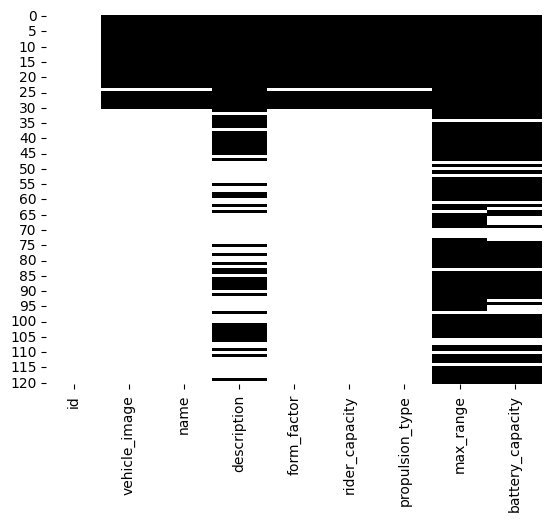

In [171]:
sns.heatmap(df_bike_types.isna(), cbar=False, cmap='binary')
plt.show()

In [172]:
for propulsion_type in ["electric", "human"]:
    subset = df_bike_types[df_bike_types["propulsion_type"] == propulsion_type]
    null_counts = subset.isnull().sum()
    null_percentages = (null_counts / len(subset) * 100).round(2)

    result = pd.DataFrame({
        "Number of null values": null_counts,
        "Percentage of null values (%)": null_percentages
    })

    print(f"\nPropulsion type: {propulsion_type}")
    print(result)


Propulsion type: electric
                  Number of null values  Percentage of null values (%)
id                                    0                           0.00
vehicle_image                         0                           0.00
name                                  0                           0.00
description                           5                          18.52
form_factor                           0                           0.00
rider_capacity                        0                           0.00
propulsion_type                       0                           0.00
max_range                            12                          44.44
battery_capacity                      5                          18.52

Propulsion type: human
                  Number of null values  Percentage of null values (%)
id                                    0                           0.00
vehicle_image                         0                           0.00
name                      

We observe a significant number of missing values requiring different handling strategies:
- Completely empty rows: Several rows contain almost no information. We must first verify if their IDs are referenced in downstream tables (like `bikes` and `trips_small`). If unreferenced, they can be safely dropped. If they are actively linked, they must be kept to preserve referential integrity, with missing strings replaced by "Unknown" and numerical values by 0.
- Random absence: `description` values are missing randomly across all bike types and can be filled with "Unknown".
- Correlated absence: `max_range` and `battery_capacity` are structurally linked. They are logically 100% missing for the `human` propulsion type (which we will fill with 0). However, they are also unexpectedly missing for a significant portion of the `electric_assist` fleet, which we will impute using the mean of the available electric bikes.

In [173]:
# Impute missing values with the means for electric propulsion types
cols = ["max_range", "battery_capacity"]
mask = df_bike_types["propulsion_type"] == "electric"
regular_mask = df_bike_types["form_factor"] == "regular"
cargo_mask = df_bike_types["form_factor"] == "cargo"


df_bike_types.loc[mask & regular_mask, cols] = df_bike_types.loc[mask & regular_mask, cols].fillna(df_bike_types.loc[mask & regular_mask, cols].mean())
df_bike_types.loc[mask & cargo_mask, cols] = df_bike_types.loc[mask & cargo_mask, cols].fillna(df_bike_types.loc[mask & cargo_mask, cols].mean())

In [174]:
# Check if the rows with all columns empty are used in df_bikes
empty_rows = df_bike_types[df_bike_types.isnull().sum(axis=1) == 8]
print("Number of rows with all columns empty : ", len(empty_rows))

ids_used = empty_rows[empty_rows["id"].isin(df_bikes["bike_type_id"])]
print("Number of id used in df_bikes : ", len(ids_used))

Number of rows with all columns empty :  30
Number of id used in df_bikes :  30


In [175]:
# Fill all missing values with "Unknown" for string columns and 0 for numeric columns
string_cols = ["vehicle_image", "name", "description", "form_factor", "propulsion_type"]
numeric_cols = ["rider_capacity", "max_range", "battery_capacity"]

df_bike_types[string_cols] = df_bike_types[string_cols].fillna("Unknown")
df_bike_types[numeric_cols] = df_bike_types[numeric_cols].fillna(0)

In [176]:
# Check if there are still any missing values
df_bike_types.isnull().sum()

id                  0
vehicle_image       0
name                0
description         0
form_factor         0
rider_capacity      0
propulsion_type     0
max_range           0
battery_capacity    0
dtype: int64

#### Dataset Visualizations

[Text(0.5, 1.0, 'Count of Bike Types'),
 Text(0.5, 0, 'Count'),
 Text(0, 0.5, 'Bike Type')]

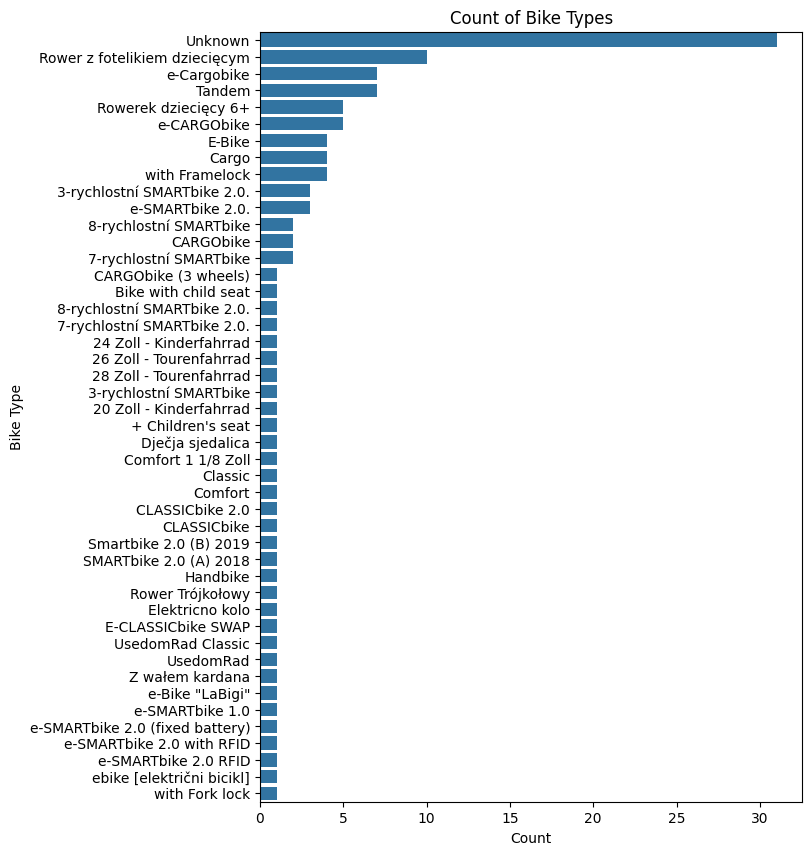

In [177]:
df_count = df_bike_types.groupby('name')["name"].count()
df_count = df_count.sort_values(ascending=False)

plt.figure(figsize=(7, 10))
sns_bar = sns.barplot(y=df_count.index, x=df_count.values)
sns_bar.set(
    title="Count of Bike Types",
    xlabel="Count", 
    ylabel="Bike Type"
)

propulsion_type
Unknown     30
electric    27
human       64
Name: propulsion_type, dtype: int64 

form_factor
Unknown    30
cargo      19
other       1
regular    71
Name: form_factor, dtype: int64


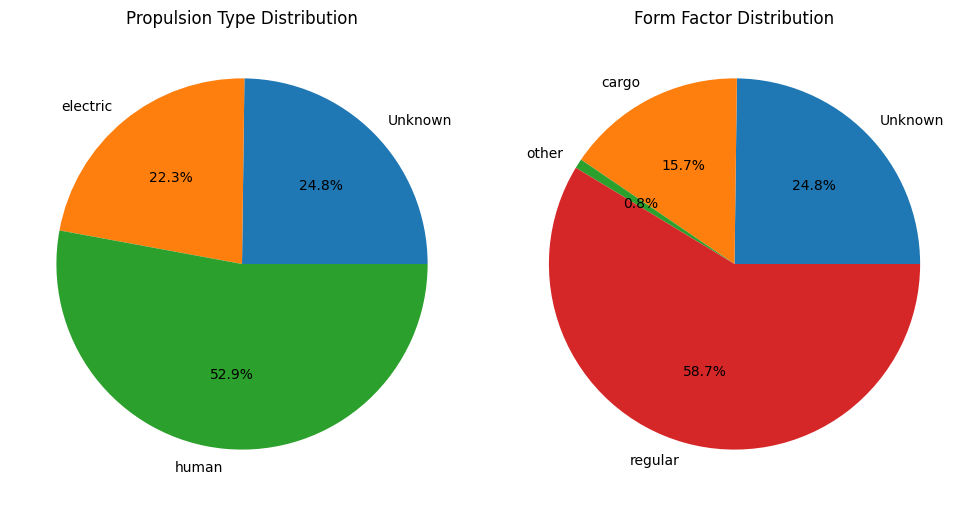

In [178]:
propulsion = df_bike_types.groupby('propulsion_type')["propulsion_type"].count()
print(propulsion, '\n')

grouped_form = df_bike_types.groupby("form_factor")["form_factor"].count()
print(grouped_form)


fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))

propulsion.plot(kind="pie", autopct="%1.1f%%",  ax=axes[0])
axes[0].set_title("Propulsion Type Distribution")

grouped_form.plot(kind="pie", autopct="%1.1f%%", ax=axes[1])
axes[1].set_title("Form Factor Distribution")

plt.tight_layout()
plt.show()

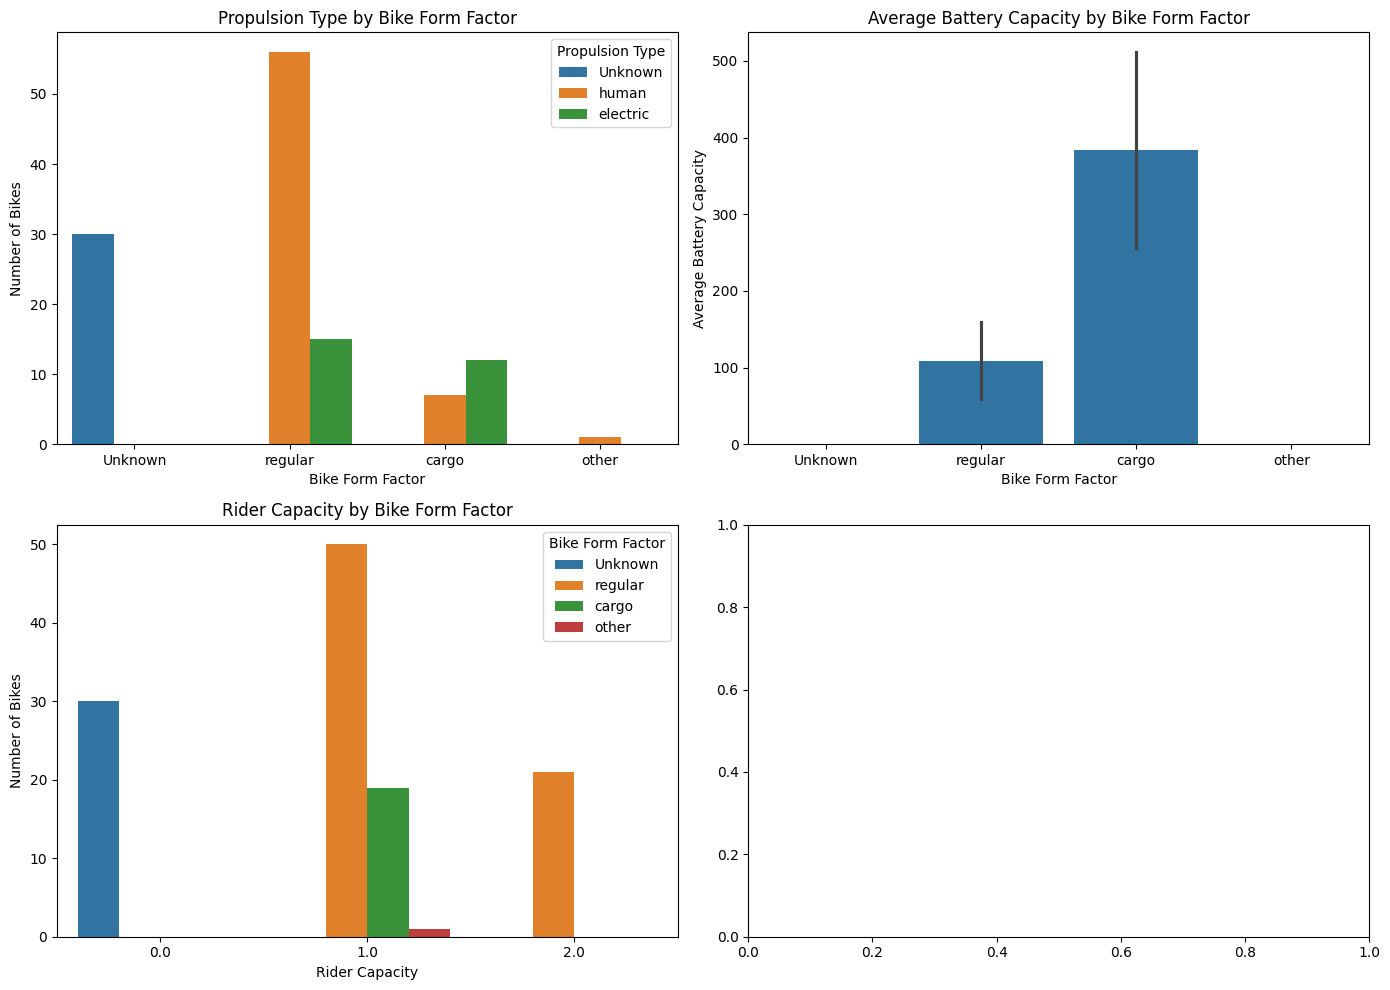

In [179]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(
    data=df_bike_types,
    x="form_factor",
    hue="propulsion_type",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Propulsion Type by Bike Form Factor")
axes[0, 0].set_xlabel("Bike Form Factor")
axes[0, 0].set_ylabel("Number of Bikes")
axes[0, 0].legend(title="Propulsion Type")

sns.barplot(
    data=df_bike_types,
    x="form_factor",
    y="battery_capacity",
    estimator="mean",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Average Battery Capacity by Bike Form Factor")
axes[0, 1].set_xlabel("Bike Form Factor")
axes[0, 1].set_ylabel("Average Battery Capacity")

sns.countplot(
    data=df_bike_types,
    x="rider_capacity",
    hue="form_factor",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Rider Capacity by Bike Form Factor")
axes[1, 0].set_xlabel("Rider Capacity")
axes[1, 0].set_ylabel("Number of Bikes")
axes[1, 0].legend(title="Bike Form Factor")

plt.tight_layout()
plt.show()

### Exploration of `stations.csv`

In [180]:
df_stations.head()

,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat
0,142186362,135,BIKE 500100,0,NaN,12,0,0,NaN,7.821669,51.677449
1,940986,176,Bahnhof Trassenmoor 5525,5525,NaN,0,6,0,NaN,13.868973,54.090538
2,93646685,176,Mutter/Vater-Kind-Kurklinik Haus Möwennest Zin...,5529,stele,0,15,0,NaN,13.918970,54.073088
3,111365509,243,Station Road,8494,smart_sign,0,20,0,NaN,-3.936120,56.119272
4,405835,302,Birkirkara Road,6868,sign,0,6,0,NaN,14.481456,35.906836


In [181]:
df_stations.info()

<class 'pandas.DataFrame'>
RangeIndex: 2932 entries, 0 to 2931
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             2932 non-null   int64  
 1   city_id        2932 non-null   int64  
 2   name           2932 non-null   str    
 3   app_number     2932 non-null   int64  
 4   terminal_type  2345 non-null   str    
 5   place_type     2932 non-null   int64  
 6   bike_racks     2932 non-null   int64  
 7   special_racks  2932 non-null   int64  
 8   rack_locks     0 non-null      float64
 9   lon            2932 non-null   float64
 10  lat            2932 non-null   float64
dtypes: float64(3), int64(6), str(2)
memory usage: 252.1 KB


In [182]:
# Calculate the total number of racks 
df_stations["total_racks"] = df_stations["bike_racks"] + df_stations["special_racks"]

df_stations[["total_racks", "bike_racks", "special_racks"]].describe()

,total_racks,bike_racks,special_racks
count,2932.000000,2932.000000,2932.000000
mean,6.022169,6.033424,-0.011255
std,6.502278,6.495116,0.486820
min,0.000000,0.000000,-10.000000
25%,0.000000,0.000000,0.000000
50%,5.000000,6.000000,0.000000
75%,10.000000,10.000000,0.000000
max,70.000000,70.000000,12.000000


In [183]:
print(df_stations["terminal_type"].unique(), '\n')
print(df_stations["place_type"].unique(), '\n')

print("Number of duplicate rows in df_stations:", df_stations.duplicated().sum())

<StringArray>
[             nan,          'stele',     'smart_sign',           'sign',
          '7inch',           'free',      'character',   'traffic_sign',
            'mmt', 'terminal_sleek',           'pult']
Length: 11, dtype: str 

[12  0  6 14  8  7 21 17 16 26 15  4 18 19 27  3] 

Number of duplicate rows in df_stations: 0


#### Missing Values Analysis and Handling

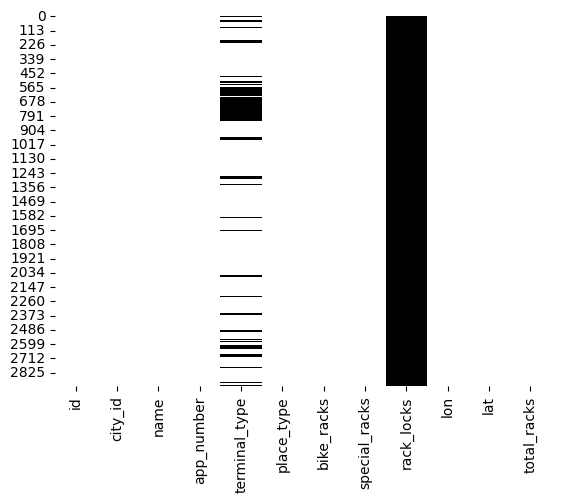

In [184]:
sns.heatmap(df_stations.isna(), cbar=False, cmap='binary')
plt.show()

We observe that the entire `rack_locks` column is missing, so we can drop it. Additionally, there are missing values in the `terminal_type` column, we replace null values with "Unknown" to create a dedicated category and prevent issues during subsequent dataset merging.

In [185]:
# Drop the 'rack_locks' column 
df_stations = df_stations.drop('rack_locks', axis=1)

In [186]:
# Replace missing values in 'terminal_type' with "Unknown"
df_stations["terminal_type"] = df_stations["terminal_type"].fillna("Unknown")

In [187]:
# Check if there are still any missing values
df_stations.isnull().sum()

id               0
city_id          0
name             0
app_number       0
terminal_type    0
place_type       0
bike_racks       0
special_racks    0
lon              0
lat              0
total_racks      0
dtype: int64

#### Dataset Visualizations

[Text(0.5, 1.0, 'Count of Terminal Types'),
 Text(0, 0.5, 'Terminal Type'),
 Text(0.5, 0, 'Count')]

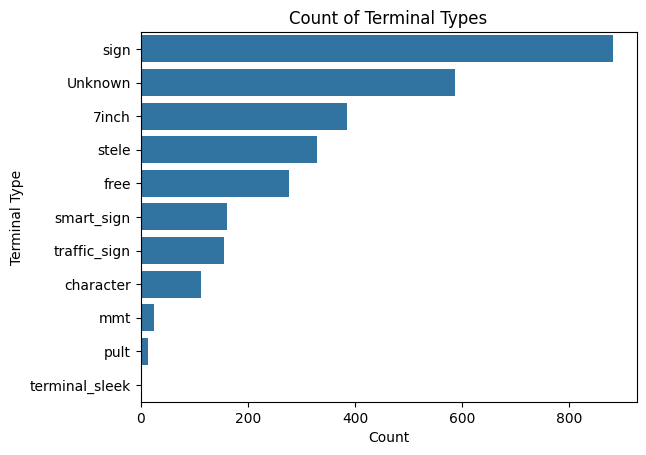

In [188]:
stations_count = df_stations['terminal_type'].value_counts()
sns_barplot = sns.barplot(
    y=stations_count.index,
    x=stations_count.values
    )
sns_barplot.set(
    title="Count of Terminal Types",
    ylabel="Terminal Type", 
    xlabel="Count"
)

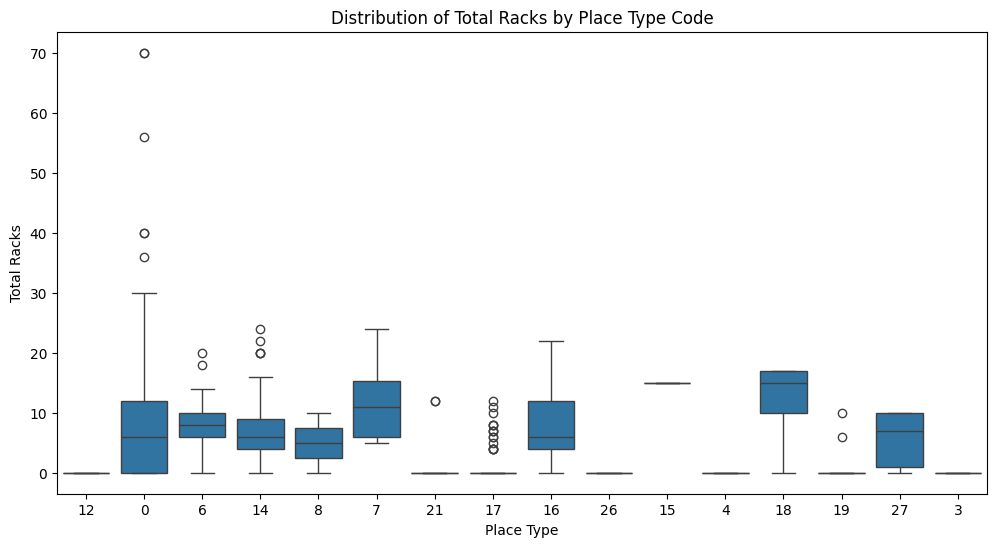

In [189]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_stations, 
    x=df_stations['place_type'].astype(str), 
    y='total_racks'
)
plt.title("Distribution of Total Racks by Place Type Code")
plt.xlabel("Place Type")
plt.ylabel("Total Racks")
plt.show()

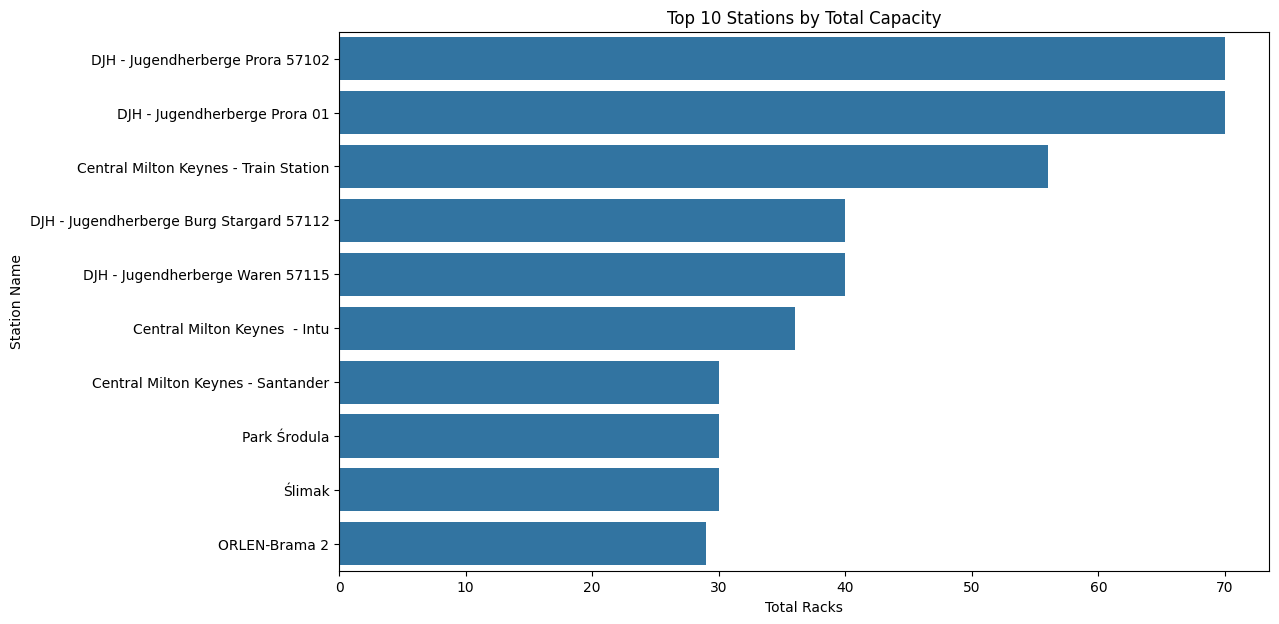

In [190]:
top_stations = df_stations.sort_values('total_racks', ascending=False).head(10)

plt.figure(figsize=(12, 7))
sns.barplot(data=top_stations, x='total_racks', y='name')
plt.title("Top 10 Stations by Total Capacity")
plt.xlabel("Total Racks")
plt.ylabel("Station Name")

plt.show()

### Exploration of `stations_status.csv`

In [191]:
df_stations_status.head()

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
0,101896428,1.661530e+09,2,0,2,0,0,False
1,54643,1.661531e+09,1,0,1,0,0,False
2,6201611,1.661531e+09,3,0,3,0,0,False
3,294346,1.661531e+09,8,0,8,0,0,False
4,781866,1.661531e+09,1,1,0,5,0,False


In [192]:
df_stations_status.info()

<class 'pandas.DataFrame'>
RangeIndex: 2925967 entries, 0 to 2925966
Data columns (total 8 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   station_id               int64  
 1   time                     float64
 2   bikes                    int64  
 3   booked_bikes             int64  
 4   bikes_available_to_rent  int64  
 5   free_racks               int64  
 6   free_special_racks       int64  
 7   maintenance              bool   
dtypes: bool(1), float64(1), int64(6)
memory usage: 159.1 MB


#### Cleaning Data
We observe that the time column is in seconds and difficult to read, so we convert time into a datetime format and extract the day, month, and hour.

In [193]:
df_stations_status["free_total_racks"] = df_stations_status["free_racks"] + df_stations_status["free_special_racks"]

In [194]:
# Convert numeric UTC timestamp (seconds) to UTC datetime
df_stations_status['datetime'] = pd.to_datetime(df_stations_status['time'], unit='s', utc=True)

df_stations_status.head()

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,free_total_racks,datetime
0,101896428,1.661530e+09,2,0,2,0,0,False,0,2022-08-26 16:14:01+00:00
1,54643,1.661531e+09,1,0,1,0,0,False,0,2022-08-26 16:15:01+00:00
2,6201611,1.661531e+09,3,0,3,0,0,False,0,2022-08-26 16:15:01+00:00
3,294346,1.661531e+09,8,0,8,0,0,False,0,2022-08-26 16:15:01+00:00
4,781866,1.661531e+09,1,1,0,5,0,False,5,2022-08-26 16:15:01+00:00


In [195]:
df_stations_status[["bikes", "booked_bikes", "bikes_available_to_rent", "free_racks", "free_special_racks","free_total_racks", "datetime"]].describe()

,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,free_total_racks
count,2.925967e+06,2.925967e+06,2.925967e+06,2.925967e+06,2.925967e+06,2.925967e+06
mean,6.186521e+00,4.599881e-02,6.141577e+00,5.030900e+00,2.216036e+00,7.246935e+00
std,6.091899e+00,4.025175e-01,6.099811e+00,5.300172e+00,4.342693e+00,8.601260e+00
min,0.000000e+00,-4.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,5.000000e+00,0.000000e+00,5.000000e+00,4.000000e+00,0.000000e+00,5.000000e+00
75%,8.000000e+00,0.000000e+00,8.000000e+00,8.000000e+00,3.000000e+00,1.200000e+01
max,1.890000e+02,3.800000e+01,1.890000e+02,7.000000e+01,3.700000e+01,8.400000e+01


In [196]:
df_stations_status['datetime'].min(), df_stations_status['datetime'].max()

(Timestamp('2022-08-26 14:48:01+0000', tz='UTC'),
 Timestamp('2023-07-15 21:59:01+0000', tz='UTC'))

#### Creating a New DataFrame 

In [197]:
cities_sub = df_cities[['id', 'timezone']]
stations_sub = df_stations[['id', 'city_id']]

stations = pd.merge(df_stations_status, stations_sub, left_on='station_id', right_on='id', how='left')
stations = pd.merge(stations, cities_sub, left_on='city_id', right_on='id', how='left')
stations.drop(columns=['id_x', 'city_id','id_y', 'time'], inplace=True, errors='ignore')

stations.head()

,station_id,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,free_total_racks,datetime,timezone
0,101896428,2,0,2,0,0,False,0,2022-08-26 16:14:01+00:00,Europe/Berlin
1,54643,1,0,1,0,0,False,0,2022-08-26 16:15:01+00:00,Europe/Berlin
2,6201611,3,0,3,0,0,False,0,2022-08-26 16:15:01+00:00,Europe/Brussels
3,294346,8,0,8,0,0,False,0,2022-08-26 16:15:01+00:00,Europe/Riga
4,781866,1,1,0,5,0,False,5,2022-08-26 16:15:01+00:00,Europe/Riga


In [198]:
#  Convert UTC datetime to local timezone datetime
stations["local_time"] = stations.apply(
    lambda row: row["datetime"].tz_convert(row["timezone"]),
    axis=1
)

stations["local_time"] = pd.to_datetime(stations["local_time"].astype(str).str[:19])
stations["hour"] = stations["local_time"].dt.hour
stations["day_of_week"] = stations["local_time"].dt.dayofweek
stations.head()

,station_id,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,free_total_racks,datetime,timezone,local_time,hour,day_of_week
0,101896428,2,0,2,0,0,False,0,2022-08-26 16:14:01+00:00,Europe/Berlin,2022-08-26 18:14:01,18,4
1,54643,1,0,1,0,0,False,0,2022-08-26 16:15:01+00:00,Europe/Berlin,2022-08-26 18:15:01,18,4
2,6201611,3,0,3,0,0,False,0,2022-08-26 16:15:01+00:00,Europe/Brussels,2022-08-26 18:15:01,18,4
3,294346,8,0,8,0,0,False,0,2022-08-26 16:15:01+00:00,Europe/Riga,2022-08-26 19:15:01,19,4
4,781866,1,1,0,5,0,False,5,2022-08-26 16:15:01+00:00,Europe/Riga,2022-08-26 19:15:01,19,4


### Exploration of `cities.csv`

In [199]:
df_cities.head()

,id,name,lat,lon,timezone,country,return_to_official_only
0,220,Zagreb,45.7984,15.98810,Europe/Berlin,HR,True
1,431,Kalisz,51.7525,18.03410,Europe/Warsaw,PL,True
2,199,Innsbruck,47.2632,11.39610,Europe/Berlin,AT,True
3,519,Siemianowice Śląskie,50.3031,19.02220,Europe/Warsaw,PL,True
4,21,Karlsruhe,49.0102,8.41827,Europe/Berlin,DE,False


In [200]:
df_cities.info()

<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       267 non-null    int64  
 1   name                     267 non-null    str    
 2   lat                      267 non-null    float64
 3   lon                      267 non-null    float64
 4   timezone                 267 non-null    str    
 5   country                  267 non-null    str    
 6   return_to_official_only  267 non-null    bool   
dtypes: bool(1), float64(2), int64(1), str(3)
memory usage: 12.9 KB


In [201]:
print("Number of duplicate: ", df_cities.duplicated().sum())
print("Number of unique timezones:", len(df_cities["timezone"].unique()))

Number of duplicate:  0
Number of unique timezones: 9


#### Dataset Visualizations

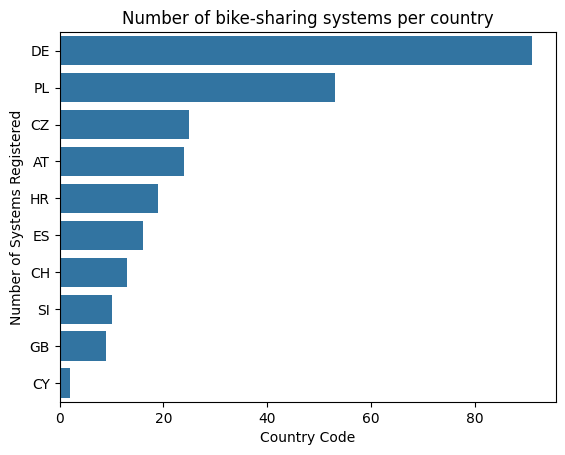

In [202]:
# Vizualization 
cities_top = df_cities["country"].value_counts().reset_index().head(10)

sns_bar = sns.barplot(
    data=cities_top,
    x="count",
    y="country"
)

sns_bar.set(
    title="Number of bike-sharing systems per country",
    xlabel="Country Code", 
    ylabel="Number of Systems Registered"
)

plt.show()

return_to_official_only
False     67
True     200
Name: return_to_official_only, dtype: int64


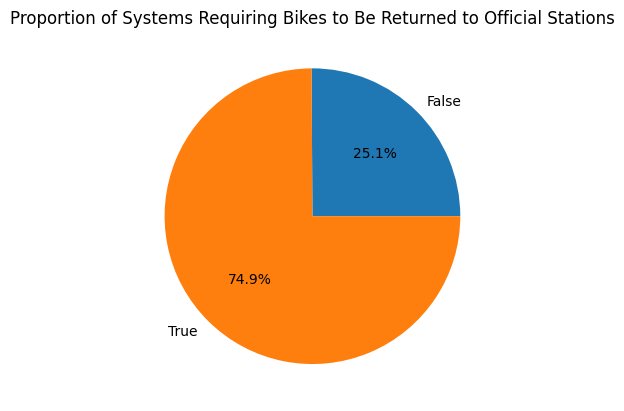

In [203]:
official_only = df_cities.groupby("return_to_official_only")["return_to_official_only"].count()
print(official_only)

official_only.plot(kind='pie', autopct="%1.1f%%")
plt.title("Proportion of Systems Requiring Bikes to Be Returned to Official Stations")
plt.show()


### Exploration of `trips_small.csv`

In [204]:
df_trips_small.head()

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,NaN,NaN,360.0,135.879806
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,NaN,NaN,1920.0,3301.514764
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,NaN,NaN,780.0,115.020620
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,NaN,NaN,540.0,1643.609250
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,NaN,NaN,4680.0,897.351993


In [205]:
df_trips_small.info()

<class 'pandas.DataFrame'>
RangeIndex: 1161376 entries, 0 to 1161375
Data columns (total 13 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   bike_id           1161376 non-null  int64  
 1   city_id           1161376 non-null  int64  
 2   time_start        1161376 non-null  float64
 3   lon_start         1161376 non-null  float64
 4   lat_start         1161376 non-null  float64
 5   lon_end           1161376 non-null  float64
 6   lat_end           1161376 non-null  float64
 7   station_id_start  1072161 non-null  float64
 8   station_id_end    1039472 non-null  float64
 9   battery_start     168532 non-null   float64
 10  battery_end       168641 non-null   float64
 11  duration          1161376 non-null  float64
 12  distance          1161376 non-null  float64
dtypes: float64(11), int64(2)
memory usage: 115.2 MB


In [206]:
df_trips_small[["battery_start", "battery_end", "duration", "distance"]].describe()

,battery_start,battery_end,duration,distance
count,168532.000000,168641.000000,1.161376e+06,1.161376e+06
mean,80.988697,76.688996,1.256241e+03,1.791774e+03
std,21.384192,22.615122,1.980838e+03,1.495191e+03
min,0.000000,0.000000,1.210000e+02,5.001365e+01
25%,66.000000,61.000000,4.800000e+02,8.851685e+02
50%,89.000000,83.000000,7.200000e+02,1.346711e+03
75%,100.000000,97.000000,1.200000e+03,2.238540e+03
max,100.000000,100.000000,2.874000e+04,1.999946e+04


In [207]:
print("Number of duplicate: ", df_trips_small.duplicated().sum())
print("Number of null values per column :")
print(df_trips_small.isnull().sum())

Number of duplicate:  0
Number of null values per column :
bike_id                  0
city_id                  0
time_start               0
lon_start                0
lat_start                0
lon_end                  0
lat_end                  0
station_id_start     89215
station_id_end      121904
battery_start       992844
battery_end         992735
duration                 0
distance                 0
dtype: int64


#### Cleaning Data

To clean the trips_small dataset, we have to apply a few changes:
- Convert `station_id_start` and `station_id_end` from floats to integers
- Transform `time_start` into datetime and `duration` in minutes
- Convert `distance` into kilometers for easier analysis

In [208]:
# Convert station_id_start and station_id_end to integers 
df_trips_small["station_id_start"] = df_trips_small["station_id_start"].astype('Int64')
df_trips_small["station_id_end"] = df_trips_small["station_id_end"].astype('Int64')

# Transform time_start into datetime and duration in minutes
df_trips_small['time_start_dt'] = pd.to_datetime(df_trips_small['time_start'], unit='s', utc=True)
df_trips_small['duration_min'] = df_trips_small['duration'] / 60

# Convert distance to kilometers 
df_trips_small['distance_km'] = df_trips_small['distance'] / 1000.0

df_trips_small.head()

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance,time_start_dt,duration_min,distance_km
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480,<NA>,NaN,NaN,360.0,135.879806,2022-11-25 11:48:01+00:00,6.0,0.135880
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472,4775153,NaN,NaN,1920.0,3301.514764,2022-12-01 12:21:01+00:00,32.0,3.301515
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153,<NA>,NaN,NaN,780.0,115.020620,2022-12-05 14:52:01+00:00,13.0,0.115021
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087,87796883,NaN,NaN,540.0,1643.609250,2022-12-06 17:43:01+00:00,9.0,1.643609
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883,87796472,NaN,NaN,4680.0,897.351993,2022-12-20 05:28:01+00:00,78.0,0.897352


In [209]:
# Check that the battery_start and battery_end columns are between 0 and 100
df_trips_small[['battery_start', 'battery_end']].describe()

,battery_start,battery_end
count,168532.000000,168641.000000
mean,80.988697,76.688996
std,21.384192,22.615122
min,0.000000,0.000000
25%,66.000000,61.000000
50%,89.000000,83.000000
75%,100.000000,97.000000
max,100.000000,100.000000


#### Missing Values Analysis and Handling

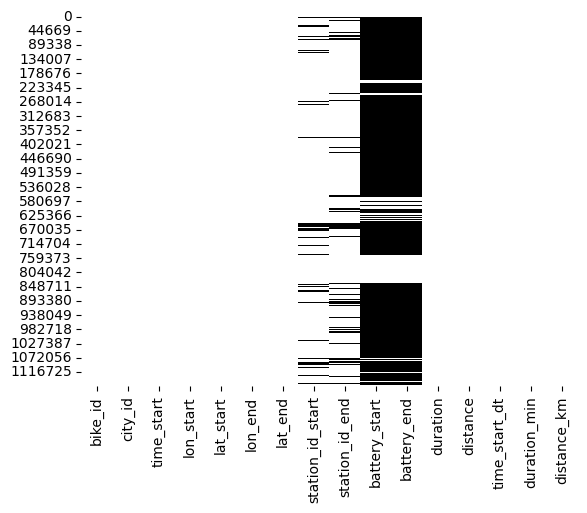

In [210]:
sns.heatmap(df_trips_small.isna(), cbar=False, cmap='binary')
plt.show()

The number of missing values in the `battery_start` and `battery_end` columns is very high. However, these columns are relevant only for electric bikes, so we have to look at the number of missing values in these columns for electric bikes only. 

Regarding the missing values in `station_id_start` and `station_id_end`, the documentation indicates that these `NaN` values correspond to free-floating trips rather than data collection errors. Therefore, we chose to retain these missing values and introduce a new categorical column to clearly distinguish between station-based and free-floating trips

In [211]:
# New columns to distinguish station-based and free-floating trips
df_trips_small['trip_type_start'] = df_trips_small['station_id_start'].apply(
    lambda x: 'Station' if pd.notnull(x) else 'Free-floating'
)

df_trips_small['trip_type_end'] = df_trips_small['station_id_end'].apply(
    lambda x: 'Station' if pd.notnull(x) else 'Free-floating'
)

df_trips_small.head()

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance,time_start_dt,duration_min,distance_km,trip_type_start,trip_type_end
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480,<NA>,NaN,NaN,360.0,135.879806,2022-11-25 11:48:01+00:00,6.0,0.135880,Station,Free-floating
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472,4775153,NaN,NaN,1920.0,3301.514764,2022-12-01 12:21:01+00:00,32.0,3.301515,Station,Station
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153,<NA>,NaN,NaN,780.0,115.020620,2022-12-05 14:52:01+00:00,13.0,0.115021,Station,Free-floating
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087,87796883,NaN,NaN,540.0,1643.609250,2022-12-06 17:43:01+00:00,9.0,1.643609,Station,Station
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883,87796472,NaN,NaN,4680.0,897.351993,2022-12-20 05:28:01+00:00,78.0,0.897352,Station,Station


In [212]:
# Merging df_trips_small with df_bikes and df_bike_types to get only the electric bikes
bike_sub = df_bikes[['id', 'bike_type_id']]
bike_types_sub = df_bike_types[['id', 'name', 'propulsion_type', 'form_factor', 'rider_capacity', 'max_range', 'battery_capacity']]

trips_with_bikes = pd.merge(df_trips_small, bike_sub, left_on='bike_id', right_on='id', how='left')
trips_with_bike_types = pd.merge(trips_with_bikes, bike_types_sub, left_on="bike_type_id", right_on="id", how="left")

trips_with_bike_types = trips_with_bike_types.drop(columns=['id_x', 'id_y'])

trips_with_bike_types.head()

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,...,distance_km,trip_type_start,trip_type_end,bike_type_id,name,propulsion_type,form_factor,rider_capacity,max_range,battery_capacity
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480,<NA>,NaN,...,0.135880,Station,Free-floating,15,with Fork lock,human,regular,1.0,0.0,0.0
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472,4775153,NaN,...,3.301515,Station,Station,15,with Fork lock,human,regular,1.0,0.0,0.0
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153,<NA>,NaN,...,0.115021,Station,Free-floating,15,with Fork lock,human,regular,1.0,0.0,0.0
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087,87796883,NaN,...,1.643609,Station,Station,15,with Fork lock,human,regular,1.0,0.0,0.0
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883,87796472,NaN,...,0.897352,Station,Station,15,with Fork lock,human,regular,1.0,0.0,0.0


In [213]:
# Impute missing values for battery_start and battery_end for human propulsion types with 0
mask_human = trips_with_bike_types['propulsion_type'] == 'human'
mask_unknown = trips_with_bike_types['propulsion_type'] == 'Unknown'
trips_with_bike_types.loc[mask_human | mask_unknown, ['battery_start', 'battery_end']] = trips_with_bike_types.loc[mask_human | mask_unknown, ['battery_start', 'battery_end']].fillna(0)

In [214]:
temp = trips_with_bike_types[trips_with_bike_types['propulsion_type'] == 'electric']

null_counts = temp.isnull().sum()
null_percentages = (null_counts / len(temp) * 100).round(2)
null_df = pd.DataFrame({
    "Number of null values": null_counts,
    "Percentage of null values (%)": null_percentages
})

print("Number of null values per column :")
print(null_df)

null_counts = trips_with_bike_types.isnull().sum()
null_percentages = (null_counts / len(trips_with_bike_types) * 100).round(2)
null_df = pd.DataFrame({
    "Number of null values": null_counts,
    "Percentage of null values (%)": null_percentages
})

print("Number of null values per column :")
print(null_df)

Number of null values per column :
                  Number of null values  Percentage of null values (%)
bike_id                               0                           0.00
city_id                               0                           0.00
time_start                            0                           0.00
lon_start                             0                           0.00
lat_start                             0                           0.00
lon_end                               0                           0.00
lat_end                               0                           0.00
station_id_start                   8836                           4.91
station_id_end                    10798                           6.00
battery_start                     11861                           6.59
battery_end                       11752                           6.53
duration                              0                           0.00
distance                              0   

Some trips with an e-bike have missing values in the battery_start and battery_end columns. This can be due to a complete battery discharge, the use of the bike without electric assistance, or simply a sensor error. Since these missing values represent only 6% of the e-bike subset and 1% of the entire dataset, we chose to remove these rows.

In [215]:
trips_with_bike_types = trips_with_bike_types.dropna(subset=['battery_start', 'battery_end'], how='any')
trips_with_bike_types.isna().sum()

bike_id                  0
city_id                  0
time_start               0
lon_start                0
lat_start                0
lon_end                  0
lat_end                  0
station_id_start     87746
station_id_end      120263
battery_start            0
battery_end              0
duration                 0
distance                 0
time_start_dt            0
duration_min             0
distance_km              0
trip_type_start          0
trip_type_end            0
bike_type_id             0
name                     0
propulsion_type          0
form_factor              0
rider_capacity           0
max_range                0
battery_capacity         0
dtype: int64

### Merging Tables

In [216]:
trip_bike = trips_with_bike_types

cities_sub = df_cities[['id', 'name', 'country', 'timezone']]

trip_bike_sub = trip_bike[['bike_id', 'bike_type_id', 'station_id_start', 'station_id_end', 'city_id', 
                            'time_start_dt', 'duration_min', 'distance_km', 'battery_start', 'battery_end', 
                            'trip_type_start', 'trip_type_end',
                            'propulsion_type', 'form_factor', 'rider_capacity', 'max_range', 'battery_capacity']]

trip_city = pd.merge(
    trip_bike_sub,
    cities_sub,
    left_on='city_id',
    right_on='id',
    how='left',
    suffixes=('', '_city')
)

trip_city = trip_city.drop(columns=['id'], errors='ignore')
trip_city = trip_city.rename(columns={'name': 'bike_sharing_system'})
trip_city.columns

Index(['bike_id', 'bike_type_id', 'station_id_start', 'station_id_end',
       'city_id', 'time_start_dt', 'duration_min', 'distance_km',
       'battery_start', 'battery_end', 'trip_type_start', 'trip_type_end',
       'propulsion_type', 'form_factor', 'rider_capacity', 'max_range',
       'battery_capacity', 'bike_sharing_system', 'country', 'timezone'],
      dtype='str')

In [217]:
keep_col = [
    'bike_id', 'propulsion_type', 'form_factor', 
    'duration_min', 'distance_km', 'battery_start', 'battery_end',
    'time_start_dt', 'station_id_start', 'station_id_end', 
    'bike_sharing_system', 'country', 'timezone'
]

clean_trip = trip_city[keep_col]

clean_trip.head()

,bike_id,propulsion_type,form_factor,duration_min,distance_km,battery_start,battery_end,time_start_dt,station_id_start,station_id_end,bike_sharing_system,country,timezone
0,11462,human,regular,6.0,0.135880,0.0,0.0,2022-11-25 11:48:01+00:00,126084480,<NA>,Wiesbaden,DE,Europe/Berlin
1,11462,human,regular,32.0,3.301515,0.0,0.0,2022-12-01 12:21:01+00:00,87796472,4775153,Wiesbaden,DE,Europe/Berlin
2,11462,human,regular,13.0,0.115021,0.0,0.0,2022-12-05 14:52:01+00:00,4775153,<NA>,Wiesbaden,DE,Europe/Berlin
3,11462,human,regular,9.0,1.643609,0.0,0.0,2022-12-06 17:43:01+00:00,4775087,87796883,Wiesbaden,DE,Europe/Berlin
4,11462,human,regular,78.0,0.897352,0.0,0.0,2022-12-20 05:28:01+00:00,87796883,87796472,Wiesbaden,DE,Europe/Berlin


In [218]:
# Convert UTC datetime to local timezone datetime
clean_trip["time_start_local"] = clean_trip.apply(
    lambda row: row["time_start_dt"].tz_convert(row["timezone"]),
    axis=1
)

clean_trip["time_start_local"] = pd.to_datetime(clean_trip["time_start_local"].astype(str).str[:19])
clean_trip["time_start_hour"] = clean_trip["time_start_local"].dt.hour

In [219]:
clean_trip['speed_kmh'] = clean_trip['distance_km'] / (clean_trip['duration_min'] / 60)

clean_trip['battery_consumed'] = 0
clean_trip.loc[clean_trip['propulsion_type'] == 'electric', 'battery_consumed'] = clean_trip.loc[clean_trip['propulsion_type'] == 'electric', 'battery_start'] - clean_trip.loc[clean_trip['propulsion_type'] == 'electric', 'battery_end']

clean_trip.head()

,bike_id,propulsion_type,form_factor,duration_min,distance_km,battery_start,battery_end,time_start_dt,station_id_start,station_id_end,bike_sharing_system,country,timezone,time_start_local,time_start_hour,speed_kmh,battery_consumed
0,11462,human,regular,6.0,0.135880,0.0,0.0,2022-11-25 11:48:01+00:00,126084480,<NA>,Wiesbaden,DE,Europe/Berlin,2022-11-25 12:48:01,12,1.358798,0
1,11462,human,regular,32.0,3.301515,0.0,0.0,2022-12-01 12:21:01+00:00,87796472,4775153,Wiesbaden,DE,Europe/Berlin,2022-12-01 13:21:01,13,6.190340,0
2,11462,human,regular,13.0,0.115021,0.0,0.0,2022-12-05 14:52:01+00:00,4775153,<NA>,Wiesbaden,DE,Europe/Berlin,2022-12-05 15:52:01,15,0.530864,0
3,11462,human,regular,9.0,1.643609,0.0,0.0,2022-12-06 17:43:01+00:00,4775087,87796883,Wiesbaden,DE,Europe/Berlin,2022-12-06 18:43:01,18,10.957395,0
4,11462,human,regular,78.0,0.897352,0.0,0.0,2022-12-20 05:28:01+00:00,87796883,87796472,Wiesbaden,DE,Europe/Berlin,2022-12-20 06:28:01,6,0.690271,0


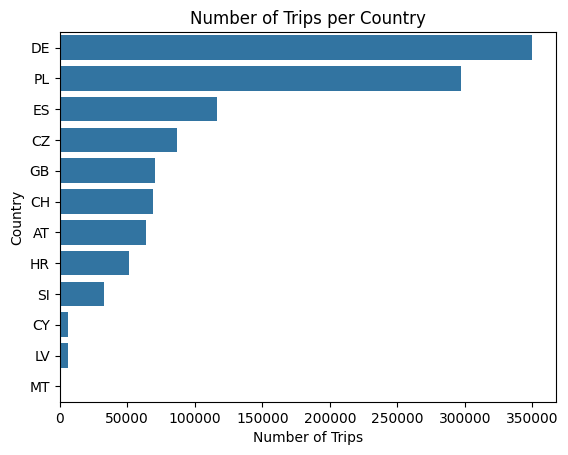

In [220]:
grouped_country_trips = clean_trip.groupby('country').size().sort_values(ascending=False)
sns.barplot(
    x=grouped_country_trips.values, 
    y=grouped_country_trips.index
)
plt.title("Number of Trips per Country")
plt.xlabel("Number of Trips")
plt.ylabel("Country")
plt.show()

C:\Users\dgtrh\AppData\Local\Temp\ipykernel_27952\2224528024.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(


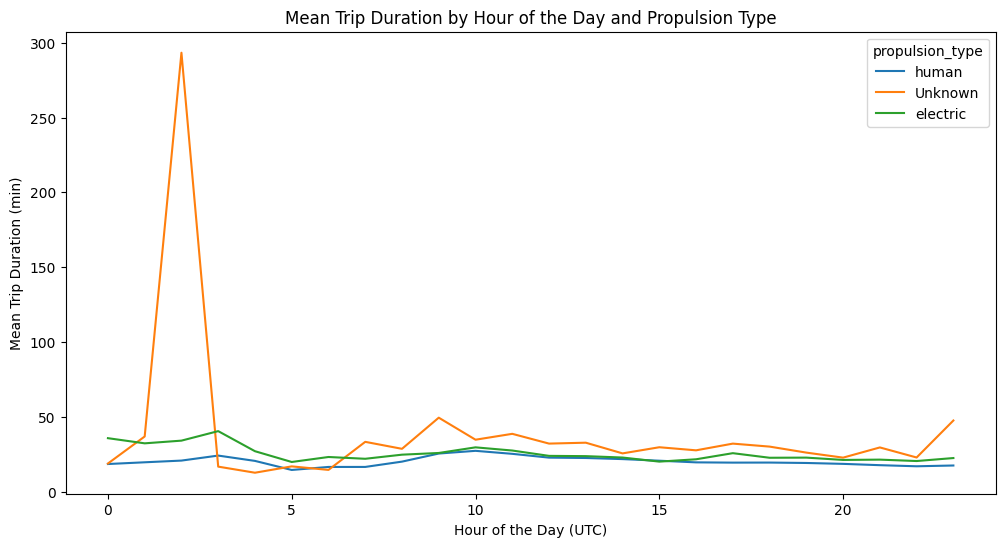

In [221]:
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=clean_trip, 
    x='time_start_hour', 
    y='duration_min', 
    hue='propulsion_type', 
    estimator='mean',
    ci=None
)
plt.title("Mean Trip Duration by Hour of the Day and Propulsion Type")
plt.xlabel("Hour of the Day (UTC)")
plt.ylabel("Mean Trip Duration (min)")
plt.show()

The bikes with an undefined propulsion type showed abnormal curves, so we decided to remove them.

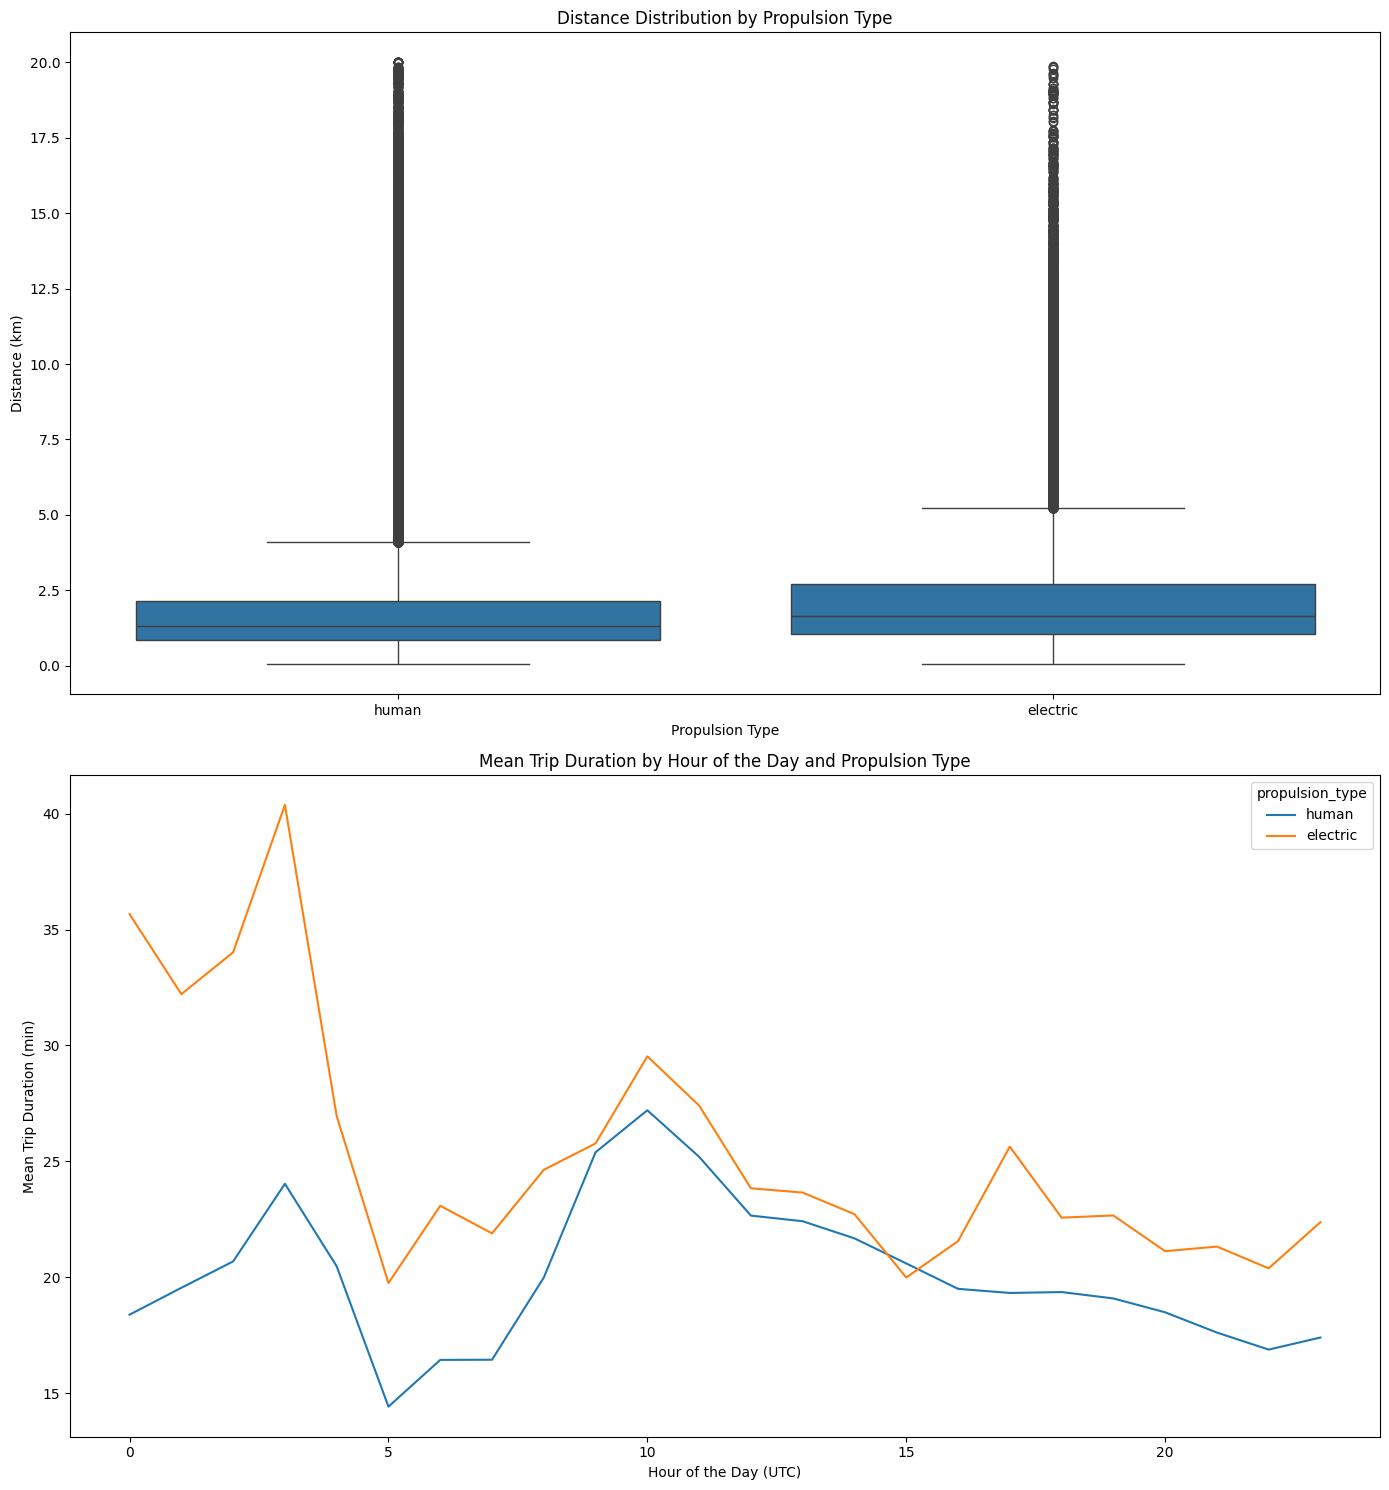

In [222]:
clean_trip = clean_trip[clean_trip['propulsion_type'].isin(['electric', 'human'])]

fig, axes = plt.subplots(2, 1, figsize=(14, 15))

sns.boxplot(data=clean_trip, x='propulsion_type', y='distance_km', ax=axes[0])
axes[0].set_title("Distance Distribution by Propulsion Type")
axes[0].set_ylabel("Distance (km)")
axes[0].set_xlabel("Propulsion Type")

sns.lineplot(data=clean_trip, x='time_start_hour', y='duration_min', hue='propulsion_type', estimator='mean', errorbar=None, ax=axes[1])
axes[1].set_title("Mean Trip Duration by Hour of the Day and Propulsion Type")
axes[1].set_xlabel("Hour of the Day (UTC)")
axes[1].set_ylabel("Mean Trip Duration (min)")

plt.tight_layout()
plt.show()

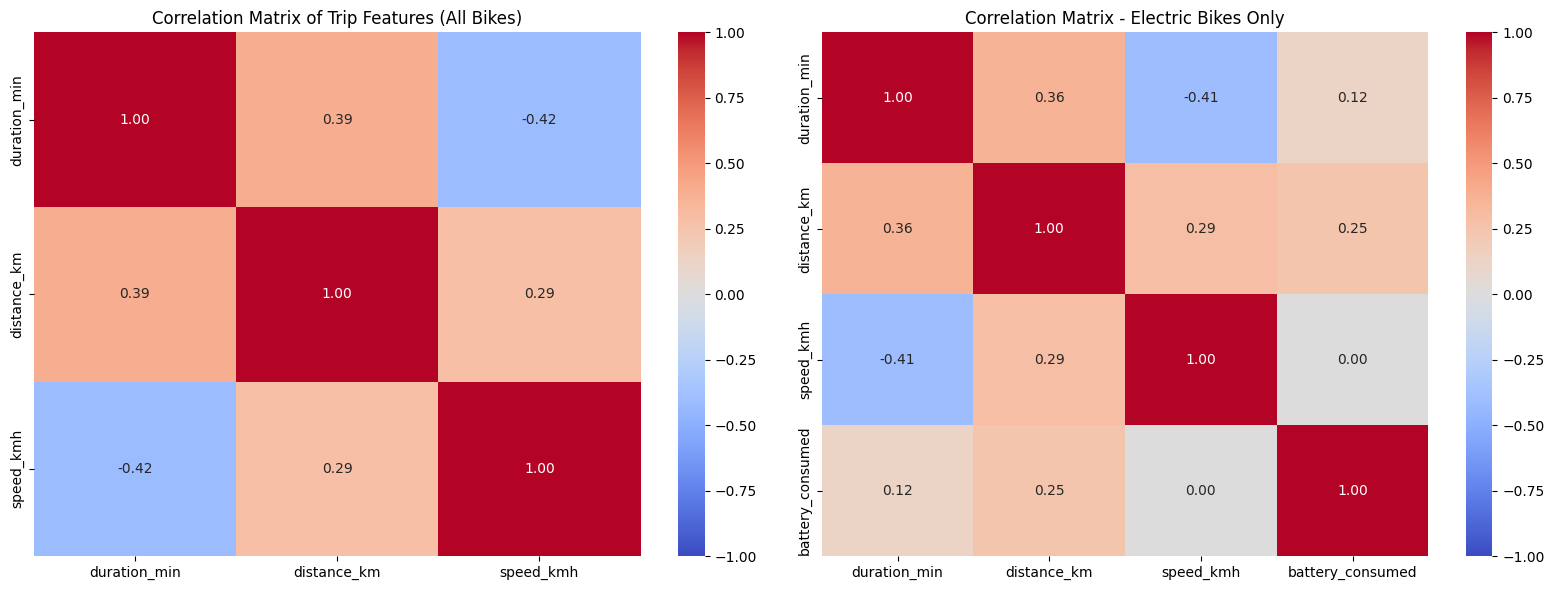

In [223]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

num_cols_all = ['duration_min', 'distance_km', 'speed_kmh']
corr_matrix_all = clean_trip[num_cols_all].corr()

sns.heatmap(corr_matrix_all, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlation Matrix of Trip Features (All Bikes)")


clean_trip_electric = clean_trip[clean_trip['propulsion_type'] == 'electric']
num_cols_elec = ['duration_min', 'distance_km', 'speed_kmh', 'battery_consumed']
corr_matrix_elec = clean_trip_electric[num_cols_elec].corr()

sns.heatmap(corr_matrix_elec, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Correlation Matrix - Electric Bikes Only")

plt.tight_layout()
plt.show()

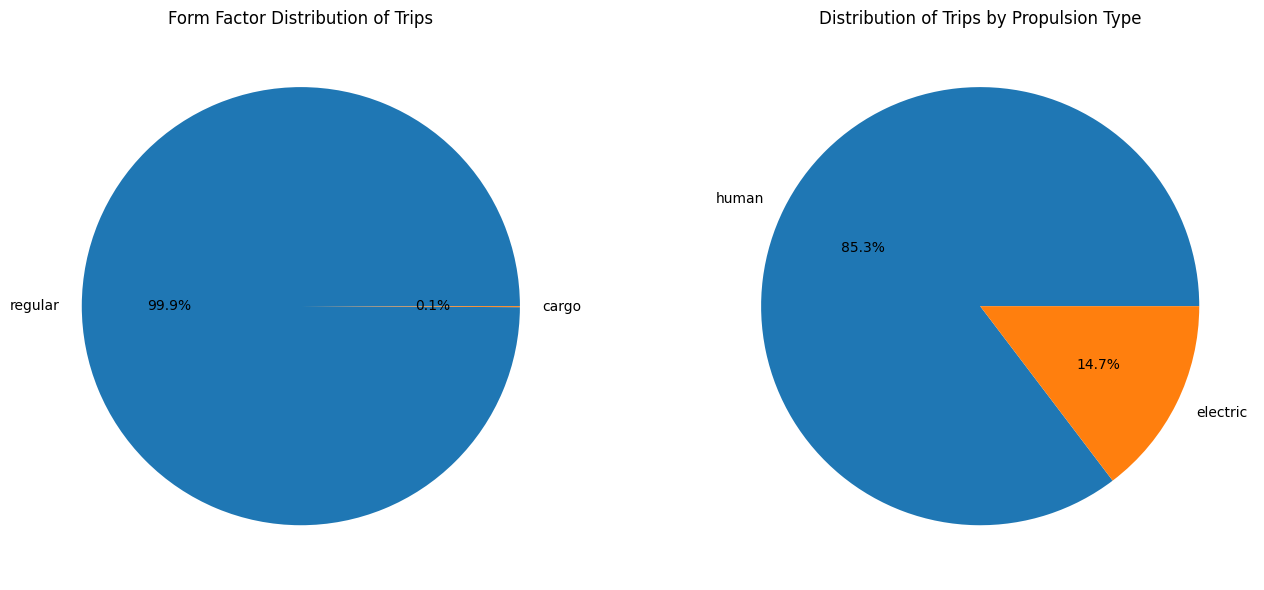

In [224]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

form_counts = clean_trip['form_factor'].value_counts()
axes[0].pie(form_counts.values, labels=form_counts.index, autopct='%1.1f%%')
axes[0].set_title("Form Factor Distribution of Trips")

prop_counts = clean_trip['propulsion_type'].value_counts()
axes[1].pie(prop_counts.values, labels=prop_counts.index, autopct='%1.1f%%')
axes[1].set_title("Distribution of Trips by Propulsion Type")

plt.tight_layout()
plt.show()

## Unsupervised Tasks: Bike Trip and Stations Profiles

### Part A - Clustering Bike Trips

### Part B - Clustering Bike-Sharing Stations

## Supervised Task: Predict Station Availability

### Preparation of the Dataset

In [225]:
test = stations.sort_values(by=['station_id', 'local_time']).reset_index(drop=True)
test["maintenance"] = test["maintenance"].astype(int)

test.head()

,station_id,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,free_total_racks,datetime,timezone,local_time,hour,day_of_week
0,94,5,0,5,0,0,0,0,2022-08-29 13:12:01+00:00,Europe/Berlin,2022-08-29 15:12:01,15,0
1,94,4,0,4,0,0,0,0,2022-08-29 13:13:01+00:00,Europe/Berlin,2022-08-29 15:13:01,15,0
2,94,5,0,5,0,0,0,0,2022-08-30 13:30:01+00:00,Europe/Berlin,2022-08-30 15:30:01,15,1
3,94,4,0,4,0,0,0,0,2022-08-31 17:57:01+00:00,Europe/Berlin,2022-08-31 19:57:01,19,2
4,94,5,0,5,0,0,0,0,2022-08-31 18:05:01+00:00,Europe/Berlin,2022-08-31 20:05:01,20,2


In [226]:
df = test.copy()   

df = df.sort_values("local_time").reset_index(drop=True)
df["end"] = df.groupby("station_id")["local_time"].transform("max")

df["target_date"] = df["local_time"] + pd.Timedelta(hours=1)
df["past_date"] = df["local_time"] - pd.Timedelta(hours=1)

# Future state of the station (1 hour later)
future_state = df[["station_id", "local_time", "bikes_available_to_rent"]].rename(
                   columns={"local_time": "found_date", "bikes_available_to_rent": "y"})
df = pd.merge_asof(df, future_state,
                   left_on="target_date", right_on="found_date",
                   by="station_id", direction="backward")             

# Next state after the future state to avoid long data gaps
next_state = df[["station_id", "local_time"]].rename(
                 columns={"local_time": "next_date"})
df = pd.merge_asof(df, next_state,
                   left_on="target_date", right_on="next_date",
                   by="station_id", direction="forward")

# Past state of the station (1 hour earlier)
past_state = df[["station_id", "local_time", "bikes_available_to_rent"]].rename(
                 columns={"local_time": "past_date", "bikes_available_to_rent": "past_bikes"})
df = pd.merge_asof(df, past_state,
                   left_on="past_date", right_on="past_date",
                   by="station_id", direction="backward")

df["delta_bikes"] = df["bikes_available_to_rent"] - df["past_bikes"]

df = df[df["next_date"].notna() & (df["next_date"] - df["found_date"] <= pd.Timedelta("24h"))]
df = df.dropna(subset=["y"])
df = df.drop(columns=["target_date", "found_date", "past_date", "next_date", "timezone"])

data = df[df["local_time"] + pd.Timedelta(hours=1) <= df["end"]].copy()
data.sort_values(by=["station_id", "local_time"]).head()

,station_id,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,free_total_racks,datetime,local_time,hour,day_of_week,end,y,past_bikes,delta_bikes
144119,94,6,0,6,0,0,0,0,2022-09-04 15:38:01+00:00,2022-09-04 17:38:01,17,6,2023-07-15 11:25:01,7,5.0,1.0
144139,94,7,0,7,0,0,0,0,2022-09-04 15:39:01+00:00,2022-09-04 17:39:01,17,6,2023-07-15 11:25:01,7,5.0,2.0
200510,94,5,0,5,0,0,0,0,2022-09-08 10:17:01+00:00,2022-09-08 12:17:01,12,3,2023-07-15 11:25:01,6,6.0,-1.0
292089,94,4,0,4,0,0,0,0,2022-09-15 13:15:01+00:00,2022-09-15 15:15:01,15,3,2023-07-15 11:25:01,4,5.0,-1.0
381434,94,7,0,7,0,0,0,0,2022-09-24 15:23:01+00:00,2022-09-24 17:23:01,17,5,2023-07-15 11:25:01,7,5.0,2.0


In [227]:
first_df = data[["station_id", "local_time", "datetime",
                 "bikes", "booked_bikes", "free_racks", "free_special_racks", "free_total_racks", "maintenance", 
                 "day_of_week", "hour", "past_bikes", "delta_bikes",
                 "bikes_available_to_rent", "y"]].copy()
first_df = first_df.dropna(subset=["past_bikes", "delta_bikes"])
first_df.head()

,station_id,local_time,datetime,bikes,booked_bikes,free_racks,free_special_racks,free_total_racks,maintenance,day_of_week,hour,past_bikes,delta_bikes,bikes_available_to_rent,y
115,278900,2022-08-26 16:51:01,2022-08-26 15:51:01+00:00,12,0,7,0,7,1,4,16,9.0,3.0,12,11
446,2528336,2022-08-26 17:10:01,2022-08-26 16:10:01+00:00,4,0,9,9,18,0,4,17,5.0,-1.0,4,4
668,6344982,2022-08-26 17:24:01,2022-08-26 16:24:01+00:00,4,0,8,0,8,0,4,17,4.0,0.0,4,1
678,724351,2022-08-26 17:24:01,2022-08-26 16:24:01+00:00,20,0,14,14,28,1,4,17,16.0,4.0,20,18
720,2528336,2022-08-26 17:26:01,2022-08-26 16:26:01+00:00,4,0,10,10,20,0,4,17,5.0,-1.0,4,3


In [228]:
first_df.info() 

<class 'pandas.DataFrame'>
Index: 2735547 entries, 115 to 2925612
Data columns (total 15 columns):
 #   Column                   Dtype             
---  ------                   -----             
 0   station_id               int64             
 1   local_time               datetime64[us]    
 2   datetime                 datetime64[s, UTC]
 3   bikes                    int64             
 4   booked_bikes             int64             
 5   free_racks               int64             
 6   free_special_racks       int64             
 7   free_total_racks         int64             
 8   maintenance              int64             
 9   day_of_week              int32             
 10  hour                     int32             
 11  past_bikes               float64           
 12  delta_bikes              float64           
 13  bikes_available_to_rent  int64             
 14  y                        int64             
dtypes: datetime64[s, UTC](1), datetime64[us](1), float64(2), int32(

### Model Training and Evaluation

In [261]:
RANDOM_STATE = 42

target = "y"
first_features = ["bikes", "booked_bikes", "free_total_racks", "maintenance", "day_of_week", "hour", "delta_bikes", "bikes_available_to_rent"]
first_df.sort_values(by="datetime", inplace=True)

x_train, x_test, y_train, y_test = train_test_split(first_df[first_features], first_df[target], test_size=0.3, shuffle=False, random_state=RANDOM_STATE)
model_evaluation = {}

x_train_sample, y_train_sample = resample(x_train, y_train, n_samples=2000, random_state=RANDOM_STATE)

In [262]:
def optimize_params(model, param_grid, x_train, y_train, x_test, y_test, scoring='r2', cv=3, n_iter=10, random_state=RANDOM_STATE):
    
    random_search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grid,
        n_iter=n_iter,
        scoring=scoring,
        cv=cv,
        n_jobs=-1,
        random_state=random_state
    )
    random_search.fit(x_train, y_train)
    best_params = random_search.best_params_
    
    return best_params

def evaluate_model(model, x_train, y_train, x_test, y_test):
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    return mae, rmse, r2

#### KNN

In [270]:
params = {
    'n_neighbors': [3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

knn_model = KNeighborsRegressor()
best_params = optimize_params(knn_model, params, 
                              x_train_sample, y_train_sample, x_test, y_test)

knn_model = KNeighborsRegressor(**best_params)
mae, rmse, r2 = evaluate_model(knn_model, x_train, y_train, x_test, y_test)

model_evaluation["KNN"] = {
    "best_params": best_params,
    "mae": mae,
    "rmse": rmse,
    "r2": r2
}

#### Decision Tree

In [271]:
params = {
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

decision_tree_model = DecisionTreeRegressor()
best_params = optimize_params(decision_tree_model, params, 
                              x_train_sample, y_train_sample, x_test, y_test)

decision_tree_model = DecisionTreeRegressor(**best_params)
mae, rmse, r2 = evaluate_model(decision_tree_model, x_train, y_train, x_test, y_test)

model_evaluation["Decision Tree"] = {
    "best_params": best_params,
    "mae": mae,
    "rmse": rmse,
    "r2": r2
}

#### Random Forest

In [272]:
params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

random_forest_model = RandomForestRegressor()
best_params = optimize_params(random_forest_model, params, 
                              x_train_sample, y_train_sample, x_test, y_test)
                              
random_forest_model = RandomForestRegressor(**best_params)
mae, rmse, r2 = evaluate_model(random_forest_model, x_train, y_train, x_test, y_test)

model_evaluation["Random Forest"] = {
    "best_params": best_params,
    "mae": mae,
    "rmse": rmse,
    "r2": r2
}


#### Gradient Boosting

In [273]:
params = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.1, 0.01, 0.001],
    "max_depth": [3, 5, 7],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

gradient_boosting_model = GradientBoostingRegressor()
best_params = optimize_params(gradient_boosting_model, params,
                              x_train_sample, y_train_sample, x_test, y_test)

gradient_boosting_model = GradientBoostingRegressor(**best_params)
mae, rmse, r2 = evaluate_model(gradient_boosting_model, x_train, y_train, x_test, y_test)

model_evaluation["Gradient Boosting"] = {
    "best_params": best_params,
    "mae": mae,
    "rmse": rmse,
    "r2": r2
}

#### Dummy Models

In [274]:
y_pred_mean = np.full_like(y_test, fill_value=y_train.mean(), dtype=float)

model_evaluation["Baseline (Mean)"] = {
    "best_params": None,
    "mae": mean_absolute_error(y_test, y_pred_mean),
    "rmse": np.sqrt(mean_squared_error(y_test, y_pred_mean)),
    "r2": r2_score(y_test, y_pred_mean)
}

In [275]:
y_pred_persistence = x_test['bikes_available_to_rent'].values

model_evaluation["Baseline (Persistence t = t+1)"] = {
    "best_params": None,
    "mae": mean_absolute_error(y_test, y_pred_persistence),
    "rmse": np.sqrt(mean_squared_error(y_test, y_pred_persistence)),
    "r2": r2_score(y_test, y_pred_persistence)
}   

#### Display Results

In [276]:
df_evaluation = pd.DataFrame.from_dict(model_evaluation, orient='index')

colonnes_ordre = ['r2', 'rmse', 'mae', 'best_params']
df_evaluation = df_evaluation[colonnes_ordre]

pd.set_option('display.max_colwidth', None)    
pd.set_option('display.max_columns', None) 
pd.set_option('display.max_rows', None)

display(df_evaluation.sort_values(by='r2', ascending=False))

,r2,rmse,mae,best_params
Gradient Boosting,0.880439,1.780367,1.098771,"{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 3, 'learning_rate': 0.1}"
Random Forest,0.874766,1.822111,1.109279,"{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 5}"
Decision Tree,0.872928,1.835436,1.120170,"{'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 5}"
Baseline (Persistence t = t+1),0.872462,1.838798,1.035850,None
KNN,0.852061,1.980411,1.277770,"{'weights': 'distance', 'n_neighbors': 7, 'metric': 'euclidean'}"
Baseline (Mean),-0.010658,5.176265,3.821165,None


### Second set (added `trips_small` informations)

In [ ]:
trips = clean_trip.copy()
trips["time_end"] = trips["time_start_local"] + pd.to_timedelta(trips["duration_min"], unit="min")

start = trips.dropna(subset=["station_id_start"])[["station_id_start", "time_start_local"]]
start.columns = ["station_id", "date"]
start["start"] = 1
start["end"] = 0

end = trips.dropna(subset=["station_id_end"])[["station_id_end", "time_end"]]
end.columns = ["station_id", "date"]
end["start"] = 0
end["end"] = 1

events = pd.concat([start, end]).sort_values("date")
events["departs_cumul"] = events.groupby("station_id")["start"].cumsum()
events["arrivees_cumul"] = events.groupby("station_id")["end"].cumsum()

events = events[["station_id", "date", "departs_cumul", "arrivees_cumul"]]

# Needed for the merge_asof 
events["date"] = events["date"].astype("datetime64[us]")
data["station_id"] = data["station_id"].astype("Int64")

# Cumulative number of departures and arrivals at time t and 1 hour before t
for time, h in [("t", 0), ("t-1", 1)]:
    data["target_date"] = (data["local_time"] - pd.Timedelta(hours=h))
    data = pd.merge_asof(data.sort_values("target_date"),
                         events.rename(columns={"date": "found_date", 
                                                "departs_cumul": f"dep_{time}",
                                                "arrivees_cumul": f"arr_{time}"}),
                         left_on="target_date", right_on="found_date",
                         by="station_id", direction="backward")
    data = data.drop(columns=["target_date", "found_date"])

# Number of departures and arrivals in the last hour
data["departs_1h"] = data["dep_t"].fillna(0) - data["dep_t-1"].fillna(0)
data["arrivees_1h"] = data["arr_t"].fillna(0) - data["arr_t-1"].fillna(0)
data["flux_net_1h"] = data["arrivees_1h"] - data["departs_1h"]
data = data.drop(columns=["dep_t", "dep_t-1", "arr_t", "arr_t-1"])

second_df = data[["station_id", 
                 "bikes", "booked_bikes", "free_racks", "free_special_racks", "free_total_racks", "capacity", "maintenance", 
                 "day_of_week", "is_weekend", "hour", 
                 "departs_1h", "arrivees_1h", "flux_net_1h",
                 "bikes_available_to_rent", "y"]].copy()
second_df.head()

In [ ]:
a = data[["station_id", "local_time", "departs_1h", "arrivees_1h", "flux_net_1h", "bikes_available_to_rent", "hour", "y"]]
a.sort_values(["station_id", "local_time"]).head()

In [ ]:
data["delta"] = data["y"] - data["bikes_available_to_rent"]

coupure = data["local_time"].quantile(0.8)
train = data[data["local_time"] < coupure - pd.Timedelta("1h")].copy()
valid = data[data["local_time"] >= coupure].copy()

# profil : écart moyen par station, heure et week-end, appris sur le TRAIN seulement
cles = ["station_id", "hour", "is_weekend"]
profil = train.groupby(cles)["delta"].agg(s="sum", n="count")
train = train.join(profil, on=cles)
valid = valid.join(profil, on=cles)

# pour une ligne du train, on retire sa propre valeur (sinon le modèle verrait sa réponse)
train["profil_delta"] = (train["s"] - train["delta"]) / (train["n"] - 1)
valid["profil_delta"] = valid["s"] / valid["n"]

# niveau moyen et volatilité de chaque station
station = train.groupby("station_id").agg(niveau_station=("bikes_available_to_rent", "mean"),
                                          volat_station=("delta", lambda x: x.abs().mean()))
train = train.join(station, on="station_id")
valid = valid.join(station, on="station_id")
train["ecart_niveau"] = train["bikes_available_to_rent"] - train["niveau_station"]
valid["ecart_niveau"] = valid["bikes_available_to_rent"] - valid["niveau_station"]

variables = ["booked_bikes", "free_racks", "free_special_racks", "free_total_racks", "capacity",
             "day_of_week", "is_weekend", "maintenance", "departs_1h", "arrivees_1h", "flux_net_1h",
             REF, "hour", "profil_delta", "niveau_station", "volat_station", "ecart_niveau"]